In [2]:
import os, glob, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

DATA_DIR = r"C:\Dev\exotrac_paper\processed_data"
SAVE_DIR = r"C:\Dev\exotrac_paper\checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

IMG_SIZE = 256
MAX_KPTS = 8
BATCH_SIZE = 8
EPOCHS = 60
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Using Device: cuda | GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [3]:
class ContainerPoseSegDataset(Dataset):

  def __init__(self, split_dir, augment=False):
    files = sorted(glob.glob(os.path.join(split_dir, "*.npz")))
    self.augment = augment
    self.samples = []
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    for f in files:
      with np.load(f) as d:
        orig_h, orig_w = d["sem_mask"].shape[:2]
        scale_x = IMG_SIZE / float(orig_w)
        scale_y = IMG_SIZE / float(orig_h)

        img = (
            torch.from_numpy(d["image"].astype(np.float32) / 255.0)
            .permute(2, 0, 1)
            .unsqueeze(0)
        )
        img = (
            F.interpolate(
                img,
                size=(IMG_SIZE, IMG_SIZE),
                mode="bilinear",
                align_corners=False,
            )
            .squeeze(0)
            .permute(1, 2, 0)
            .numpy()
        )
        img = img[:, :, ::-1].copy()

        sem = (
            torch.from_numpy(d["sem_mask"].astype(np.float32))
            .unsqueeze(0)
            .unsqueeze(0)
        )
        sem = (
            F.interpolate(sem, size=(IMG_SIZE, IMG_SIZE), mode="nearest")
            .squeeze()
            .long()
            .numpy()
        )

        vf = torch.from_numpy(d["vec_field"].astype(np.float32)).unsqueeze(0)
        vf = (
            F.interpolate(
                vf,
                size=(IMG_SIZE, IMG_SIZE),
                mode="bilinear",
                align_corners=False,
            )
            .squeeze(0)
            .numpy()
        )

        vm = torch.from_numpy(d["vec_mask"].astype(np.float32)).unsqueeze(0)
        vm = (
            F.interpolate(vm, size=(IMG_SIZE, IMG_SIZE), mode="nearest")
            .squeeze(0)
            .numpy()
        )

        kpts = d["kpts"].astype(np.float32).copy()
        valid = kpts[:, 0] >= 0
        kpts[valid, 0] *= scale_x
        kpts[valid, 1] *= scale_y

      self.samples.append((img, sem, vf, vm, kpts, mean, std))

  def __len__(self):
    return len(self.samples)

  def __getitem__(self, idx):
    img, sem_mask, vec_field, vec_mask, kpts, mean, std = self.samples[idx]
    if self.augment and np.random.rand() < 0.5:
      img = np.clip(img * np.random.uniform(0.8, 1.2), 0.0, 1.0)
    img = np.transpose((img - mean) / std, (2, 0, 1))
    return (
        torch.from_numpy(img),
        torch.from_numpy(sem_mask),
        torch.from_numpy(vec_field),
        torch.from_numpy(vec_mask),
        torch.from_numpy(kpts),
    )

In [4]:
import os
print(os.listdir("checkpoints"))

['best_clean_4kpt.pth', 'best_corner_net.pth', 'best_paper_model.pth', 'last_paper_model.pth', 'sharp_pvnet.pth', 'stable_corner_net.pth', 'stable_corner_net_512.pth', 'stable_corner_net_finetuned.pth']


In [5]:
import os, glob

ROBOFLOW_DIR = "."
for split in ["train", "valid", "test"]:
    imgs = glob.glob(os.path.join(ROBOFLOW_DIR, split, "images", "*.*"))
    lbls = glob.glob(os.path.join(ROBOFLOW_DIR, split, "labels", "*.txt"))
    print(f"{split}: {len(imgs)} images, {len(lbls)} labels")

sample_lbl = sorted(glob.glob(os.path.join(ROBOFLOW_DIR, "train", "labels", "*.txt")))[0]
with open(sample_lbl) as f:
    print("Sample label line:", f.readline().strip()[:120])

train: 167 images, 167 labels
valid: 46 images, 46 labels
test: 23 images, 23 labels
Sample label line: 0 0.2013888888888889 0.7725694444444444 0.2065972222222222 0.7777777777777778 0.21875 0.7760416666666666 0.2413194444444


Running 512x512 upgrade on device: cuda
Built 167 512x512 .npz samples for [train]
Built 46 512x512 .npz samples for [valid]
Built 23 512x512 .npz samples for [test]
Warm-started from: checkpoints/stable_corner_net_finetuned.pth

Starting 25-epoch 512x512 fine-tuning...
Epoch 01/25 | Train Loss: 0.8676 | Val Loss: 0.9071  <-- saved best 512
Epoch 02/25 | Train Loss: 0.6437 | Val Loss: 0.8572  <-- saved best 512
Epoch 03/25 | Train Loss: 0.5712 | Val Loss: 0.8384  <-- saved best 512
Epoch 04/25 | Train Loss: 0.4975 | Val Loss: 0.8203  <-- saved best 512
Epoch 05/25 | Train Loss: 0.4537 | Val Loss: 0.8132  <-- saved best 512
Epoch 06/25 | Train Loss: 0.4314 | Val Loss: 0.8237
Epoch 07/25 | Train Loss: 0.3970 | Val Loss: 0.8053  <-- saved best 512
Epoch 08/25 | Train Loss: 0.3904 | Val Loss: 0.8122
Epoch 09/25 | Train Loss: 0.3541 | Val Loss: 0.7838  <-- saved best 512
Epoch 10/25 | Train Loss: 0.3431 | Val Loss: 0.8025
Epoch 11/25 | Train Loss: 0.3221 | Val Loss: 0.8065
Epoch 12/25 | Tra

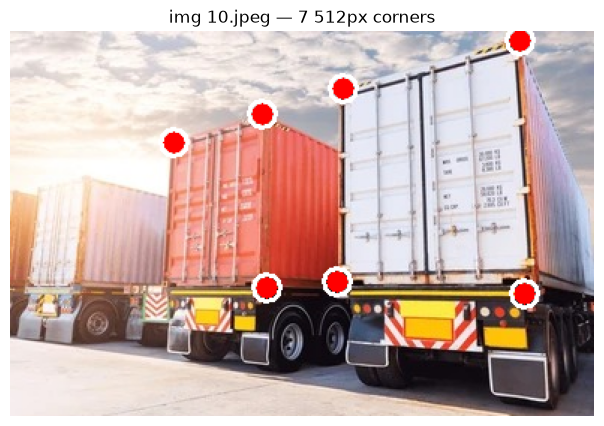

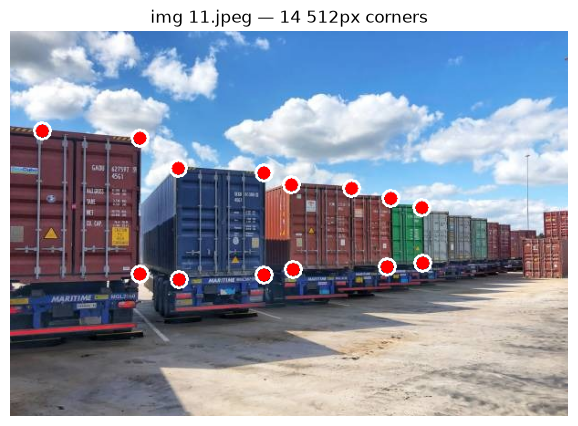

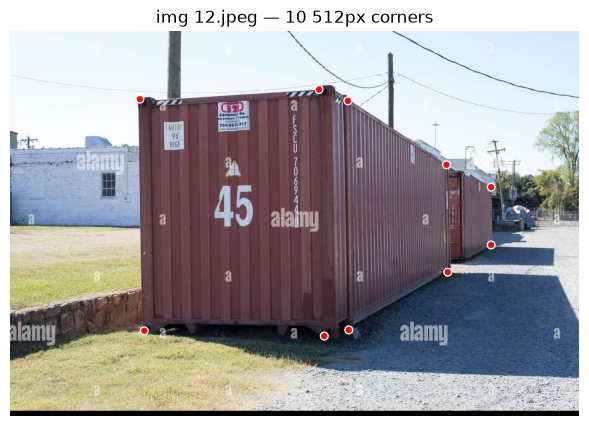

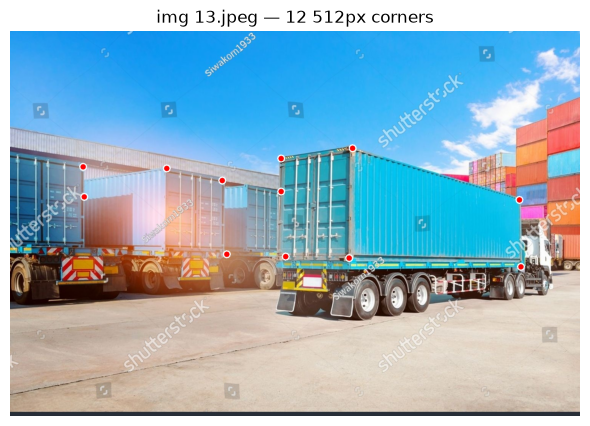

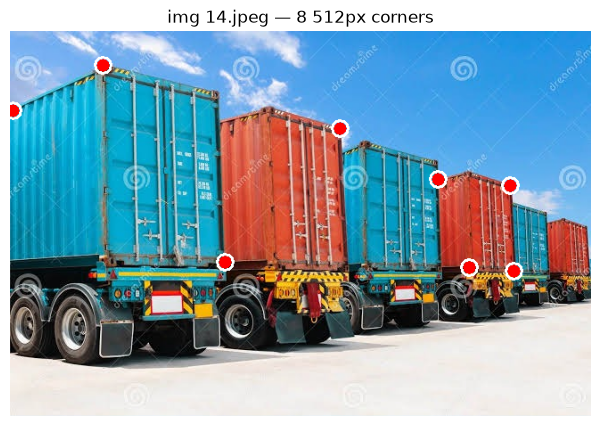

...

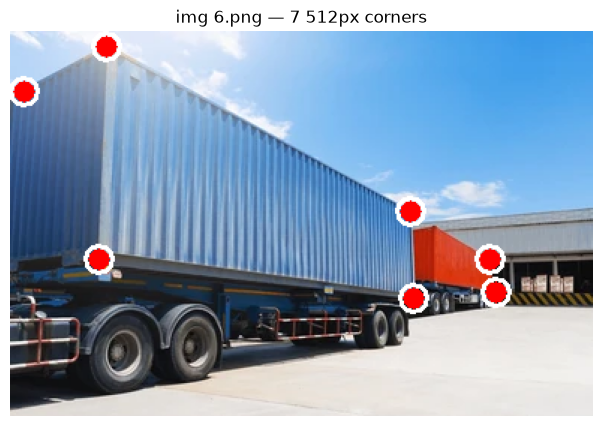

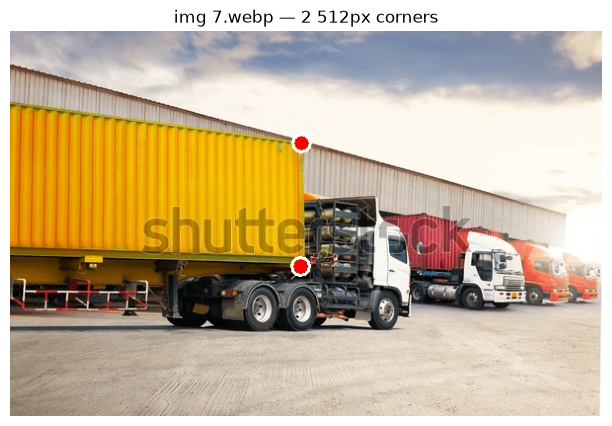

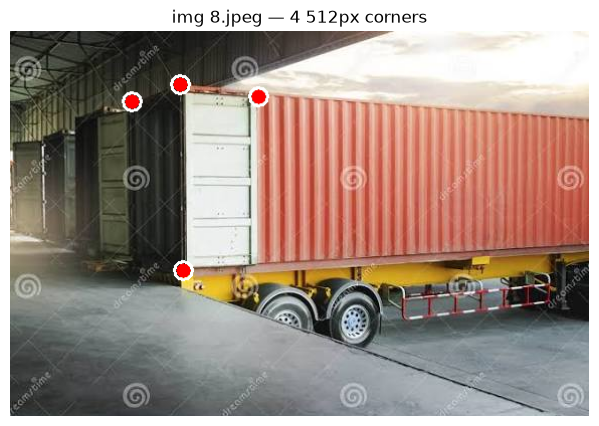

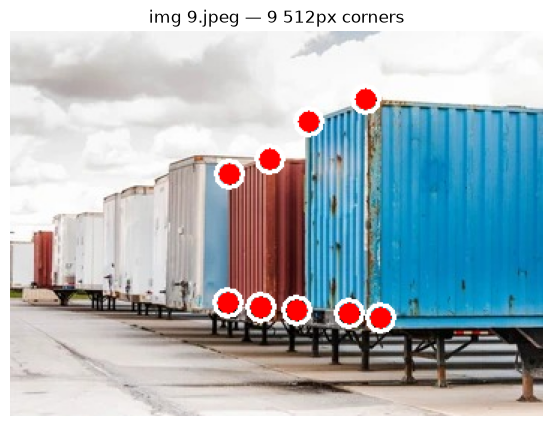

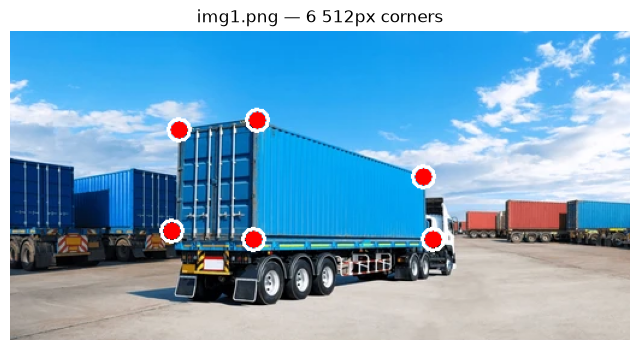

In [7]:
import os, glob, cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import matplotlib.pyplot as plt

IMG_SIZE = 512
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running 512x512 upgrade on device:", DEVICE)

# ==========================================
# STEP 1: Build Clean 512x512 .npz Dataset (Filtering Collinear Edge Vertices)
# ==========================================
OUT_NPZ_DIR = "processed_data_512"

def filter_true_polygon_corners(pts, angle_thresh_deg=166.0, margin=4.0, size=512):
    """Keeps only sharp geometric corners of a polygon, dropping straight-edge midpoints and frame-border points."""
    n = len(pts)
    if n < 3:
        return []
    corners = []
    for i in range(n):
        p_prev = pts[(i - 1) % n]
        p_curr = pts[i]
        p_next = pts[(i + 1) % n]

        x, y = p_curr
        # Ignore dummy points clipped on the image frame edge
        if x <= margin or x >= size - 1 - margin or y <= margin or y >= size - 1 - margin:
            continue

        v1 = p_prev - p_curr
        v2 = p_next - p_curr
        n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
        if n1 < 1e-3 or n2 < 1e-3:
            continue

        cos_ang = np.clip(np.dot(v1, v2) / (n1 * n2), -1.0, 1.0)
        angle = np.degrees(np.arccos(cos_ang))
        # Only keep vertices where the edge actually bends (rejects ~180 deg straight-line midpoints)
        if angle < angle_thresh_deg:
            corners.append(p_curr.tolist())
    return corners

def make_gaussian_heatmap(kpts, size=512, sigma=4.5):
    hm = np.zeros((size, size), dtype=np.float32)
    yy, xx = np.mgrid[0:size, 0:size]
    for x, y in kpts:
        g = np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * sigma ** 2))
        hm = np.maximum(hm, g)
    return hm

for split in ["train", "valid", "test"]:
    split_out = os.path.join(OUT_NPZ_DIR, split)
    os.makedirs(split_out, exist_ok=True)
    img_paths = sorted(glob.glob(os.path.join(split, "images", "*.*")))
    count = 0
    for img_p in img_paths:
        stem = os.path.splitext(os.path.basename(img_p))[0]
        lbl_p = os.path.join(split, "labels", stem + ".txt")
        if not os.path.exists(lbl_p):
            continue

        bgr = cv2.imread(img_p)
        if bgr is None:
            continue
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rgb_512 = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        mask_512 = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
        all_kpts = []

        with open(lbl_p, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 7:
                    continue
                coords = np.array([float(v) for v in parts[1:]], dtype=np.float32).reshape(-1, 2)
                pts_512 = coords * IMG_SIZE
                poly_int = np.round(pts_512).astype(np.int32)
                cv2.fillPoly(mask_512, [poly_int], 1)

                true_corners = filter_true_polygon_corners(pts_512, angle_thresh_deg=166.0, margin=4.0, size=IMG_SIZE)
                all_kpts.extend(true_corners)

        all_kpts = np.array(all_kpts, dtype=np.float32) if len(all_kpts) > 0 else np.zeros((0, 2), dtype=np.float32)
        hm_512 = make_gaussian_heatmap(all_kpts, size=IMG_SIZE, sigma=4.5)

        np.savez_compressed(
            os.path.join(split_out, f"{stem}.npz"),
            image=rgb_512,
            mask=mask_512,
            heatmap=hm_512
        )
        count += 1
    print(f"Built {count} 512x512 .npz samples for [{split}]")

# ==========================================
# STEP 2: 512x512 Dataset & DataLoaders
# ==========================================
class Container512Dataset(Dataset):
    def __init__(self, npz_dir, augment=False):
        self.files = sorted(glob.glob(os.path.join(npz_dir, "*.npz")))
        self.augment = augment
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        img = data["image"].copy()
        mask = data["mask"].copy()
        hm = data["heatmap"].copy()

        if self.augment:
            if np.random.rand() < 0.5:
                img = np.ascontiguousarray(img[:, ::-1, :])
                mask = np.ascontiguousarray(mask[:, ::-1])
                hm = np.ascontiguousarray(hm[:, ::-1])
            if np.random.rand() < 0.5:
                alpha = np.random.uniform(0.85, 1.15)
                beta = np.random.uniform(-15, 15)
                img = np.clip(img.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

        img_t = ((img.astype(np.float32) / 255.0 - self.mean) / self.std).transpose(2, 0, 1)
        return (
            torch.from_numpy(img_t),
            torch.from_numpy(mask).long(),
            torch.from_numpy(hm).unsqueeze(0).float()
        )

train_loader = DataLoader(Container512Dataset(os.path.join(OUT_NPZ_DIR, "train"), augment=True), batch_size=4, shuffle=True)
val_loader = DataLoader(Container512Dataset(os.path.join(OUT_NPZ_DIR, "valid"), augment=False), batch_size=4, shuffle=False)

# ==========================================
# STEP 3: Warm-Start StableCornerNet & Train at 512x512
# ==========================================
class StableCornerNet(nn.Module):
    def __init__(self):
        super().__init__()
        b = models.resnet50(weights=None)
        self.stem0 = nn.Sequential(b.conv1, b.bn1, b.relu)
        self.pool = b.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4

        self.lat1 = nn.Sequential(nn.Conv2d(256, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat2 = nn.Sequential(nn.Conv2d(512, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat3 = nn.Sequential(nn.Conv2d(1024, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat4 = nn.Sequential(nn.Conv2d(2048, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.up1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.fuse128 = nn.Sequential(nn.Conv2d(128 + 64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.seg_head = nn.Conv2d(64, 2, 1)
        self.hm_head = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(True), nn.Conv2d(32, 1, 1))

    def forward(self, x):
        s0 = self.stem0(x)
        c1 = self.layer1(self.pool(s0))
        c2 = self.layer2(c1); c3 = self.layer3(c2); c4 = self.layer4(c3)
        p1 = self.lat1(c1)
        p2 = F.interpolate(self.lat2(c2), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p3 = F.interpolate(self.lat3(c3), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p4 = F.interpolate(self.lat4(c4), size=p1.shape[2:], mode="bilinear", align_corners=False)
        f128 = self.fuse128(torch.cat([self.up1(torch.cat([p1, p2, p3, p4], dim=1)), s0], dim=1))
        feat = self.up2(f128)
        return self.seg_head(feat), self.hm_head(feat)

net = StableCornerNet().to(DEVICE)
ckpt_path = "checkpoints/stable_corner_net_finetuned.pth" if os.path.exists("checkpoints/stable_corner_net_finetuned.pth") else "checkpoints/stable_corner_net.pth"
net.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
print(f"Warm-started from: {ckpt_path}")

EPOCHS = 25
optimizer = torch.optim.AdamW(net.parameters(), lr=8e-5, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
seg_criterion = nn.CrossEntropyLoss()

def weighted_hm_loss(logits, target):
    pred = torch.sigmoid(logits)
    weights = 1.0 + 20.0 * target  # stronger focus on sharp 512x512 corner peaks
    return (weights * (pred - target) ** 2).mean()

best_val_loss = float("inf")
CKPT_512 = "checkpoints/stable_corner_net_512.pth"

print("\nStarting 25-epoch 512x512 fine-tuning...")
for epoch in range(1, EPOCHS + 1):
    net.train()
    tr_loss = 0.0
    for imgs, masks, hms in train_loader:
        imgs, masks, hms = imgs.to(DEVICE), masks.to(DEVICE), hms.to(DEVICE)
        optimizer.zero_grad()
        s_out, h_out = net(imgs)
        loss = seg_criterion(s_out, masks) + 30.0 * weighted_hm_loss(h_out, hms)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * imgs.size(0)
    scheduler.step()
    tr_loss /= len(train_loader.dataset)

    net.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, masks, hms in val_loader:
            imgs, masks, hms = imgs.to(DEVICE), masks.to(DEVICE), hms.to(DEVICE)
            s_out, h_out = net(imgs)
            loss = seg_criterion(s_out, masks) + 30.0 * weighted_hm_loss(h_out, hms)
            val_loss += loss.item() * imgs.size(0)
    val_loss /= len(val_loader.dataset)

    tag = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(net.state_dict(), CKPT_512)
        tag = "  <-- saved best 512"
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}{tag}")

# ==========================================
# STEP 4: High-Res 512x512 Inference + Collinearity Pruning
# ==========================================
def is_collinear_midpoint(pt, kept_pts, line_tol=5.5):
    px, py = pt
    n = len(kept_pts)
    for i in range(n):
        ax, ay = kept_pts[i]
        for j in range(i + 1, n):
            bx, by = kept_pts[j]
            abx, aby = bx - ax, by - ay
            ab_len2 = abx * abx + aby * aby
            if ab_len2 < 1e-4:
                continue
            t = ((px - ax) * abx + (py - ay) * aby) / ab_len2
            if 0.08 < t < 0.92:
                proj_x, proj_y = ax + t * abx, ay + t * aby
                if np.hypot(px - proj_x, py - proj_y) < line_tol:
                    return True
    return False

@torch.no_grad()
def extract_512_corners(seg_logits, hm_prob, thresh=0.28, min_dist=20.0, min_area_ratio=0.008):
    raw_mask = (seg_logits.argmax(dim=1).squeeze().cpu().numpy() > 0).astype(np.uint8)
    clean_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)))

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(clean_mask, connectivity=8)
    min_pixels = int(IMG_SIZE * IMG_SIZE * min_area_ratio)

    valid_mask = np.zeros_like(clean_mask)
    for cid in range(1, num_labels):
        if stats[cid, cv2.CC_STAT_AREA] >= min_pixels:
            valid_mask[labels == cid] = 1

    valid_mask = cv2.morphologyEx(valid_mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (11, 11)))
    mask_t = torch.from_numpy(valid_mask).float().to(hm_prob.device).unsqueeze(0).unsqueeze(0)
    mask_dil = F.max_pool2d(mask_t, kernel_size=13, stride=1, padding=6)
    hm_masked = hm_prob * mask_dil

    local_max = F.max_pool2d(hm_masked, kernel_size=11, stride=1, padding=5)
    local_avg = F.avg_pool2d(hm_masked, kernel_size=11, stride=1, padding=5)
    peaks = (hm_masked == local_max) & (hm_masked > thresh) & ((hm_masked - local_avg) > 0.07)

    ys, xs = torch.where(peaks[0, 0])
    scores = hm_masked[0, 0, ys, xs]
    if len(scores) == 0:
        return np.zeros((0, 2), dtype=np.float32)

    order = torch.argsort(scores, descending=True)
    hm_np = hm_masked[0, 0].cpu().numpy()

    kept = []
    for idx in order:
        x, y = int(xs[idx].item()), int(ys[idx].item())
        x0, x1 = max(0, x - 2), min(IMG_SIZE, x + 3)
        y0, y1 = max(0, y - 2), min(IMG_SIZE, y + 3)
        patch = hm_np[y0:y1, x0:x1]
        gy, gx = np.mgrid[y0:y1, x0:x1]
        w_sum = patch.sum() + 1e-6
        sub_x = float((patch * gx).sum() / w_sum)
        sub_y = float((patch * gy).sum() / w_sum)

        if any(np.hypot(sub_x - kx, sub_y - ky) < min_dist for kx, ky in kept):
            continue
        if is_collinear_midpoint((sub_x, sub_y), kept, line_tol=5.5):
            continue
        kept.append((sub_x, sub_y))

    return np.array(kept, dtype=np.float32)

net.load_state_dict(torch.load(CKPT_512, map_location=DEVICE))
net.eval()

OUTPUT_DIR = "test_random_512_clean"
os.makedirs(OUTPUT_DIR, exist_ok=True)
mean_rgb = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std_rgb = np.array([0.229, 0.224, 0.225], dtype=np.float32)

print("\nRunning 512x512 Inference on test_random/...")
for path in sorted(glob.glob(os.path.join("test_random", "*.*"))):
    bgr = cv2.imread(path)
    if bgr is None:
        continue
    bgr_clean = bgr[:int(bgr.shape[0] * 0.92), :]
    ch, cw = bgr_clean.shape[:2]

    rgb = cv2.cvtColor(bgr_clean, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    tensor = ((resized.astype(np.float32) / 255.0 - mean_rgb) / std_rgb).transpose(2, 0, 1)
    inp = torch.from_numpy(tensor).unsqueeze(0).to(DEVICE)

    s_out, h_logits = net(inp)
    h_prob = torch.sigmoid(h_logits)
    pred_kpts = extract_512_corners(s_out, h_prob, thresh=0.28, min_dist=20.0)

    vis = rgb.copy()
    for x512, y512 in pred_kpts:
        xo = int(round((x512 + 0.5) * cw / IMG_SIZE))
        yo = int(round((y512 + 0.5) * ch / IMG_SIZE))
        cv2.circle(vis, (xo, yo), 7, (255, 0, 0), -1)
        cv2.circle(vis, (xo, yo), 9, (255, 255, 255), 2)

    cv2.imwrite(os.path.join(OUTPUT_DIR, os.path.basename(path)), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
    plt.figure(figsize=(8, 5))
    plt.imshow(vis)
    plt.title(f"{os.path.basename(path)} — {len(pred_kpts)} 512px corners")
    plt.axis("off")
    plt.show()

This is the backup/fallback phenomena it does not have actual wheels keypoints to predict:

Mapped Ground Coordinates (X_m, Y_m):
 [[-3.09375    18.9375    ]
 [-0.28124973 18.9375    ]
 [ 0.8852458  16.032785  ]
 [ 3.540984   16.032785  ]]


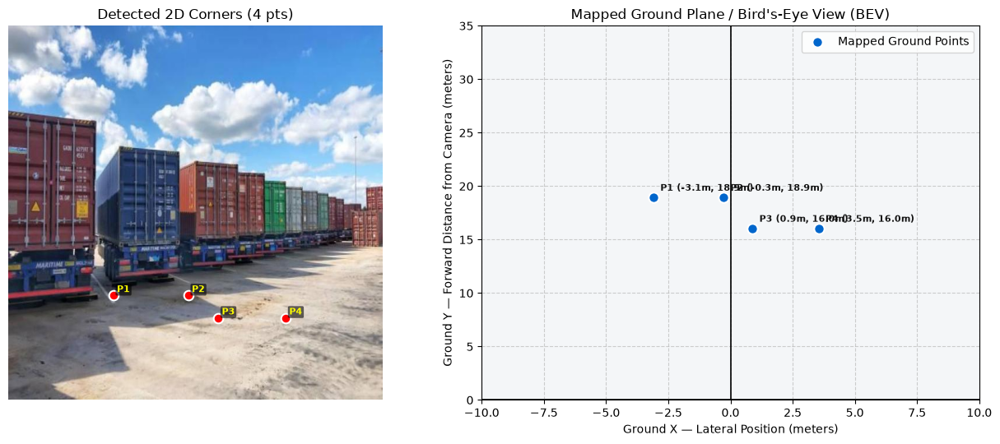

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def compute_ground_homography(src_img_pts, dst_ground_pts):
    """
    Computes Homography H mapping 2D image points (u, v) -> real-world ground (X_m, Y_m).
    src_img_pts:    (N, 2) array of 4+ points on the ground/road plane in image pixels
    dst_ground_pts: (N, 2) array of corresponding real-world ground coordinates in meters (X, Y)
    """
    src = np.asarray(src_img_pts, dtype=np.float32)
    dst = np.asarray(dst_ground_pts, dtype=np.float32)
    H, _ = cv2.findHomography(src, dst, method=cv2.RANSAC)
    return H


def map_corners_to_ground(corners_xy, H):
    """
    Maps detected 2D corner points (N, 2) in image pixels to ground coordinates (N, 2) in meters.
    """
    if corners_xy is None or len(corners_xy) == 0:
        return np.zeros((0, 2), dtype=np.float32)
    pts = np.asarray(corners_xy, dtype=np.float32).reshape(-1, 1, 2)
    ground_pts = cv2.perspectiveTransform(pts, H).reshape(-1, 2)
    return ground_pts


def visualize_2d_to_ground_bev(image_rgb, corners_2d, ground_xy, bev_xlim=(-10, 10), bev_ylim=(0, 35)):
    """
    Side-by-side visualization:
      Left:  Original image with detected 2D corner points
      Right: Ground / Bird's-Eye View (BEV) plot showing mapped positions (X, Y in meters)
    """
    fig, (ax_img, ax_bev) = plt.subplots(1, 2, figsize=(13, 5.5))

    # Left: 2D Image + Corners
    ax_img.imshow(image_rgb)
    if len(corners_2d) > 0:
        ax_img.scatter(
            corners_2d[:, 0], corners_2d[:, 1],
            c="red", edgecolors="white", s=70, linewidths=1.5, zorder=3
        )
        for idx, (x, y) in enumerate(corners_2d):
            ax_img.text(
                x + 6, y - 6, f"P{idx+1}",
                color="yellow", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="black", alpha=0.6, edgecolor="none")
            )
    ax_img.set_title(f"Detected 2D Corners ({len(corners_2d)} pts)")
    ax_img.axis("off")

    # Right: Ground / BEV Coordinates (X = lateral in meters, Y = forward distance in meters)
    ax_bev.set_facecolor("#f4f6f8")
    ax_bev.grid(True, linestyle="--", alpha=0.6)
    ax_bev.axhline(0, color="black", linewidth=1.2)
    ax_bev.axvline(0, color="black", linewidth=1.2)

    if len(ground_xy) > 0:
        ax_bev.scatter(
            ground_xy[:, 0], ground_xy[:, 1],
            c="#0066cc", edgecolors="white", s=80, linewidths=1.5, zorder=4, label="Mapped Ground Points"
        )
        for idx, (gx, gy) in enumerate(ground_xy):
            ax_bev.annotate(
                f"P{idx+1} ({gx:.1f}m, {gy:.1f}m)",
                (gx, gy),
                textcoords="offset points",
                xytext=(6, 6),
                fontsize=8,
                fontweight="bold",
                color="#111111"
            )

    ax_bev.set_xlim(bev_xlim)
    ax_bev.set_ylim(bev_ylim)
    ax_bev.set_xlabel("Ground X — Lateral Position (meters)")
    ax_bev.set_ylabel("Ground Y — Forward Distance from Camera (meters)")
    ax_bev.set_title("Mapped Ground Plane / Bird's-Eye View (BEV)")
    ax_bev.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    # 1. Load a test image (or create a dummy blank canvas if testing standalone)
    img_path = "wheel_keypoints_v1/test/images/img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg"
    bgr = cv2.imread(img_path)
    if bgr is None:
        h, w = 512, 512
        rgb = np.full((h, w, 3), 220, dtype=np.uint8)
        cv2.rectangle(rgb, (0, int(h * 0.55)), (w, h), (160, 165, 170), -1)  # mock ground
    else:
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        h, w = rgb.shape[:2]

    # 2. Example ground-plane calibration points (replace with real yard/road reference points)
    # 4 points on the ground in image pixels -> corresponding real-world (X_meters, Y_meters)
    src_ground_px = [
        [w * 0.20, h * 0.65],
        [w * 0.80, h * 0.65],
        [w * 0.35, h * 0.92],
        [w * 0.65, h * 0.92],
    ]
    dst_ground_m = [
        [-4.0, 22.0],
        [4.0, 22.0],
        [-2.5, 8.0],
        [2.5, 8.0],
    ]
    H_ground = compute_ground_homography(src_ground_px, dst_ground_m)

    # 3. Plug in your model's detected 2D corner coordinates here:
    # e.g. pred_kpts from extract_tta_adaptive_corners(...)
    detected_corners_2d = np.array([
        [w * 0.28, h * 0.72],
        [w * 0.48, h * 0.72],
        [w * 0.56, h * 0.78],
        [w * 0.74, h * 0.78],
    ], dtype=np.float32)

    # 4. Map 2D corners -> Ground coordinates & visualize
    mapped_ground_xy = map_corners_to_ground(detected_corners_2d, H_ground)
    print("This is the backup/fallback phenomena it does not have actual wheels keypoints to predict:\n")
    print("Mapped Ground Coordinates (X_m, Y_m):\n", mapped_ground_xy)

    visualize_2d_to_ground_bev(rgb, detected_corners_2d, mapped_ground_xy)




2D Points (u, v):
 [[166.19524 427.8577 ]
 [172.32632 434.52747]
 [177.38106 438.10928]]
Mapped Ground Coordinates (X_m, Y_m):
 [[-3.2488537 21.22075  ]
 [-3.1439533 20.772831 ]
 [-3.0492568 20.529358 ]]


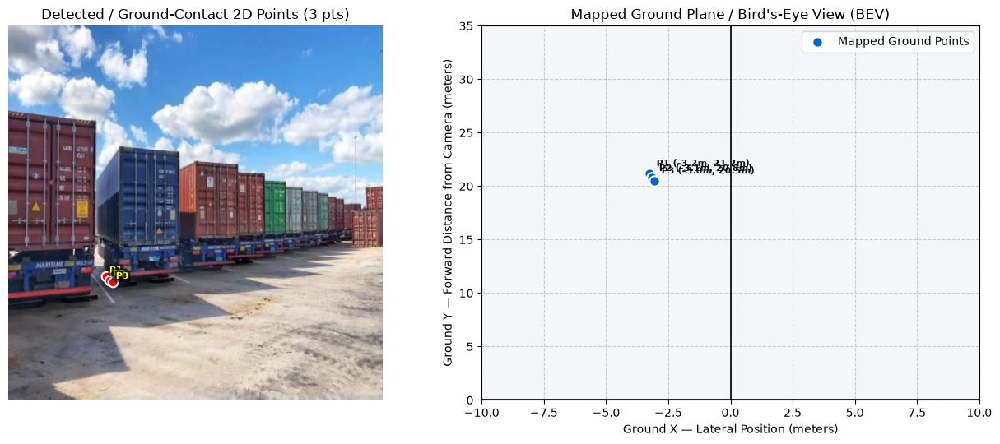

In [22]:
import json
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np


def compute_ground_homography(src_img_pts, dst_ground_pts):
    """
    Computes Homography H mapping 2D image points (u, v) -> real-world ground (X_m, Y_m).
    Requires at least 4 non-collinear point pairs.
    """
    src = np.asarray(src_img_pts, dtype=np.float32)
    dst = np.asarray(dst_ground_pts, dtype=np.float32)

    if len(src) < 4 or len(dst) < 4 or len(src) != len(dst):
        print("Warning: Need at least 4 matching (src, dst) point pairs to compute Homography.")
        return None

    H, _ = cv2.findHomography(src, dst, method=cv2.RANSAC)
    return H


def map_corners_to_ground(corners_xy, H):
    """
    Maps detected 2D corner / wheel ground-contact points (N, 2) in image pixels
    to ground coordinates (N, 2) in meters.
    """
    if H is None or corners_xy is None or len(corners_xy) == 0:
        return np.zeros((0, 2), dtype=np.float32)

    pts = np.asarray(corners_xy, dtype=np.float32).reshape(-1, 1, 2)
    ground_pts = cv2.perspectiveTransform(pts, H).reshape(-1, 2)
    return ground_pts


def load_yolo_pose_keypoints(label_path, img_w, img_h):
    """
    Reads YOLO keypoint label (.txt) lines of format:
      class_id cx cy w h x1 y1 v1 x2 y2 v2 ...
    Returns visible keypoint pixel coordinates as an (N, 2) float32 array.
    """
    label_file = Path(label_path)
    if not label_file.exists():
        return np.zeros((0, 2), dtype=np.float32)

    pts = []
    with open(label_file, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 8:
                continue
            kpt_vals = list(map(float, parts[5:]))
            # Iterate in triplets: (x_norm, y_norm, visibility)
            for i in range(0, len(kpt_vals) - 2, 3):
                kx, ky, vis = kpt_vals[i], kpt_vals[i + 1], kpt_vals[i + 2]
                if vis > 0:
                    px = kx * img_w
                    py = ky * img_h
                    pts.append([px, py])

    return np.asarray(pts, dtype=np.float32) if pts else np.zeros((0, 2), dtype=np.float32)


def load_coco_keypoints_for_image(coco_json_path, file_name):
    """
    Optional helper if annotations were exported in COCO JSON format.
    Returns visible keypoint pixel coordinates as an (N, 2) float32 array.
    """
    json_file = Path(coco_json_path)
    if not json_file.exists():
        return np.zeros((0, 2), dtype=np.float32)

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.json if hasattr(json, "json") else json.load(f)

    target_ids = {
        img["id"] for img in data.get("images", [])
        if img.get("file_name") == file_name or Path(img.get("file_name", "")).name == Path(file_name).name
    }
    if not target_ids:
        return np.zeros((0, 2), dtype=np.float32)

    pts = []
    for ann in data.get("annotations", []):
        if ann.get("image_id") in target_ids:
            kpts = ann.get("keypoints", [])
            for i in range(0, len(kpts) - 2, 3):
                x, y, v = kpts[i], kpts[i + 1], kpts[i + 2]
                if v > 0:
                    pts.append([float(x), float(y)])

    return np.asarray(pts, dtype=np.float32) if pts else np.zeros((0, 2), dtype=np.float32)


def visualize_2d_to_ground_bev(image_rgb, corners_2d, ground_xy, bev_xlim=(-10, 10), bev_ylim=(0, 35)):
    """
    Side-by-side visualization:
      Left:  Original image with 2D points
      Right: Ground / Bird's-Eye View (BEV) plot showing mapped positions (X, Y in meters)
    """
    fig, (ax_img, ax_bev) = plt.subplots(1, 2, figsize=(13, 5.5))

    # Left: 2D Image + Points
    ax_img.imshow(image_rgb)
    if len(corners_2d) > 0:
        ax_img.scatter(
            corners_2d[:, 0], corners_2d[:, 1],
            c="red", edgecolors="white", s=70, linewidths=1.5, zorder=3
        )
        for idx, (x, y) in enumerate(corners_2d):
            ax_img.text(
                x + 6, y - 6, f"P{idx + 1}",
                color="yellow", fontsize=8, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="black", alpha=0.6, edgecolor="none")
            )
    ax_img.set_title(f"Detected / Ground-Contact 2D Points ({len(corners_2d)} pts)")
    ax_img.axis("off")

    # Right: Ground / BEV Coordinates (X = lateral in meters, Y = forward distance in meters)
    ax_bev.set_facecolor("#f4f6f8")
    ax_bev.grid(True, linestyle="--", alpha=0.6)
    ax_bev.axhline(0, color="black", linewidth=1.2)
    ax_bev.axvline(0, color="black", linewidth=1.2)

    if len(ground_xy) > 0:
        ax_bev.scatter(
            ground_xy[:, 0], ground_xy[:, 1],
            c="#0066cc", edgecolors="white", s=80, linewidths=1.5, zorder=4, label="Mapped Ground Points"
        )
        for idx, (gx, gy) in enumerate(ground_xy):
            ax_bev.annotate(
                f"P{idx + 1} ({gx:.1f}m, {gy:.1f}m)",
                (gx, gy),
                textcoords="offset points",
                xytext=(6, 6),
                fontsize=8,
                fontweight="bold",
                color="#111111"
            )

    ax_bev.set_xlim(bev_xlim)
    ax_bev.set_ylim(bev_ylim)
    ax_bev.set_xlabel("Ground X — Lateral Position (meters)")
    ax_bev.set_ylabel("Ground Y — Forward Distance from Camera (meters)")
    ax_bev.set_title("Mapped Ground Plane / Bird's-Eye View (BEV)")
    ax_bev.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    img_path = Path("wheel_keypoints_v1/test/images/img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg")
    label_path = Path("wheel_keypoints_v1/test/labels") / f"{img_path.stem}.txt"
    coco_path = Path("wheel_keypoints_v1/test/_annotations.coco.json")

    bgr = cv2.imread(str(img_path))
    if bgr is None:
        h, w = 512, 512
        rgb = np.full((h, w, 3), 220, dtype=np.uint8)
        cv2.rectangle(rgb, (0, int(h * 0.55)), (w, h), (160, 165, 170), -1)
    else:
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        h, w = rgb.shape[:2]

    # Replace src_ground_px and dst_ground_m with real ground calibration points for your scene/yard
    src_ground_px = [
        [w * 0.20, h * 0.65],
        [w * 0.80, h * 0.65],
        [w * 0.35, h * 0.92],
        [w * 0.65, h * 0.92],
    ]
    dst_ground_m = [
        [-4.0, 22.0],
        [4.0, 22.0],
        [-2.5, 8.0],
        [2.5, 8.0],
    ]
    H_ground = compute_ground_homography(src_ground_px, dst_ground_m)

    # Load real annotated wheel ground-contact keypoints if available; fallback to sample points
    pts_2d = load_yolo_pose_keypoints(label_path, w, h)
    if len(pts_2d) == 0:
        pts_2d = load_coco_keypoints_for_image(coco_path, img_path.name)
    if len(pts_2d) == 0:
        pts_2d = np.array([
            [w * 0.28, h * 0.72],
            [w * 0.48, h * 0.72],
            [w * 0.56, h * 0.78],
            [w * 0.74, h * 0.78],
        ], dtype=np.float32)

    mapped_ground_xy = map_corners_to_ground(pts_2d, H_ground)
    print("2D Points (u, v):\n", pts_2d)
    print("Mapped Ground Coordinates (X_m, Y_m):\n", mapped_ground_xy)

    visualize_2d_to_ground_bev(rgb, pts_2d, mapped_ground_xy)

In [1]:
from pathlib import Path
import cv2
import numpy as np

print("Imports OK")

test_img = Path("wheel_keypoints_v1/test/images/img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg")
print("Image exists:", test_img.exists(), "| Path:", test_img)

if test_img.exists():
  bgr = cv2.imread(str(test_img))
  print("Loaded image shape:", None if bgr is None else bgr.shape)

test_dir = Path("wheel_keypoints_v1/test")
print(
    "Files inside test:",
    [p.name for p in test_dir.rglob("*") if p.is_file()][:10],
)

Imports OK
Image exists: True | Path: wheel_keypoints_v1\test\images\img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg
Loaded image shape: (640, 640, 3)
Files inside test: ['img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg', 'img-29_jpeg_jpg.rf.c50f08a858167ca9585359ec491bb011.jpg', 'img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.txt', 'img-29_jpeg_jpg.rf.c50f08a858167ca9585359ec491bb011.txt', 'img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2-checkpoint.jpg']


In [9]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np


def compute_ground_homography(src_img_pts, dst_ground_pts):
  src = np.asarray(src_img_pts, dtype=np.float32)
  dst = np.asarray(dst_ground_pts, dtype=np.float32)
  if len(src) < 4 or len(dst) < 4 or len(src) != len(dst):
    return None
  H, _ = cv2.findHomography(src, dst, method=cv2.RANSAC)
  return H


def map_corners_to_ground(corners_xy, H):
  if H is None or corners_xy is None or len(corners_xy) == 0:
    return np.zeros((0, 2), dtype=np.float32)
  pts = np.asarray(corners_xy, dtype=np.float32).reshape(-1, 1, 2)
  return cv2.perspectiveTransform(pts, H).reshape(-1, 2)


def load_yolo_pose_keypoints(label_path, img_w, img_h):
  label_file = Path(label_path)
  if not label_file.exists():
    return np.zeros((0, 2), dtype=np.float32)
  pts = []
  with open(label_file, "r", encoding="utf-8") as f:
    for line in f:
      parts = line.strip().split()
      if len(parts) < 8:
        continue
      kpt_vals = list(map(float, parts[5:]))
      for i in range(0, len(kpt_vals) - 2, 3):
        kx, ky, vis = kpt_vals[i], kpt_vals[i + 1], kpt_vals[i + 2]
        if vis > 0:
          pts.append([kx * img_w, ky * img_h])
  return np.asarray(pts, dtype=np.float32) if pts else np.zeros((0, 2), dtype=np.float32)


img_path = Path(
    "wheel_keypoints_v1/test/images/img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg"
)
label_path = Path("wheel_keypoints_v1/test/labels") / f"{img_path.stem}.txt"

bgr = cv2.imread(str(img_path))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

pts_2d = load_yolo_pose_keypoints(label_path, w, h)
print("Loaded 2D Wheel Keypoints shape:", pts_2d.shape)
print("2D Points (u, v):\n", pts_2d)

# Replace with real yard/road ground calibration points when ready
src_ground_px = [
    [w * 0.20, h * 0.65],
    [w * 0.80, h * 0.65],
    [w * 0.35, h * 0.92],
    [w * 0.65, h * 0.92],
]
dst_ground_m = [
    [-4.0, 22.0],
    [4.0, 22.0],
    [-2.5, 8.0],
    [2.5, 8.0],
]

H_ground = compute_ground_homography(src_ground_px, dst_ground_m)
mapped_ground_xy = map_corners_to_ground(pts_2d, H_ground)
print("Mapped Ground Coordinates (X_m, Y_m):\n", mapped_ground_xy)

fig, (ax_img, ax_bev) = plt.subplots(1, 2, figsize=(13, 5.5))
ax_img.imshow(rgb)
if len(pts_2d) > 0:
  ax_img.scatter(
      pts_2d[:, 0],
      pts_2d[:, 1],
      c="red",
      edgecolors="white",
      s=70,
      linewidths=1.5,
  )
  for idx, (x, y) in enumerate(pts_2d):
    ax_img.text(
        x + 6,
        y - 6,
        f"W{idx+1}",
        color="yellow",
        fontsize=8,
        fontweight="bold",
    )
ax_img.set_title(f"Wheel Ground-Contact Keypoints ({len(pts_2d)} pts)")
ax_img.axis("off")

ax_bev.set_facecolor("#f4f6f8")
ax_bev.grid(True, linestyle="--", alpha=0.6)
ax_bev.axhline(0, color="black", linewidth=1.2)
ax_bev.axvline(0, color="black", linewidth=1.2)
if len(mapped_ground_xy) > 0:
  ax_bev.scatter(
      mapped_ground_xy[:, 0],
      mapped_ground_xy[:, 1],
      c="#0066cc",
      edgecolors="white",
      s=80,
      linewidths=1.5,
  )
  for idx, (gx, gy) in enumerate(mapped_ground_xy):
    ax_bev.annotate(
        f"W{idx+1} ({gx:.1f}m, {gy:.1f}m)",
        (gx, gy),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=8,
        fontweight="bold",
    )
ax_bev.set_xlim(-10, 10)
ax_bev.set_ylim(0, 35)
ax_bev.set_xlabel("Ground X — Lateral Position (meters)")
ax_bev.set_ylabel("Ground Y — Forward Distance from Camera (meters)")
ax_bev.set_title("Mapped Ground Plane / BEV")

plt.tight_layout()
plt.savefig("bev_img11.png", dpi=150)
plt.close(fig)
print("Saved bev_img11.png successfully!")

Loaded 2D Wheel Keypoints shape: (3, 2)
2D Points (u, v):
 [[166.19524 427.8577 ]
 [172.32632 434.52747]
 [177.38106 438.10928]]
Mapped Ground Coordinates (X_m, Y_m):
 [[-3.2488537 21.22075  ]
 [-3.1439533 20.772831 ]
 [-3.0492568 20.529358 ]]
Saved bev_img11.png successfully!


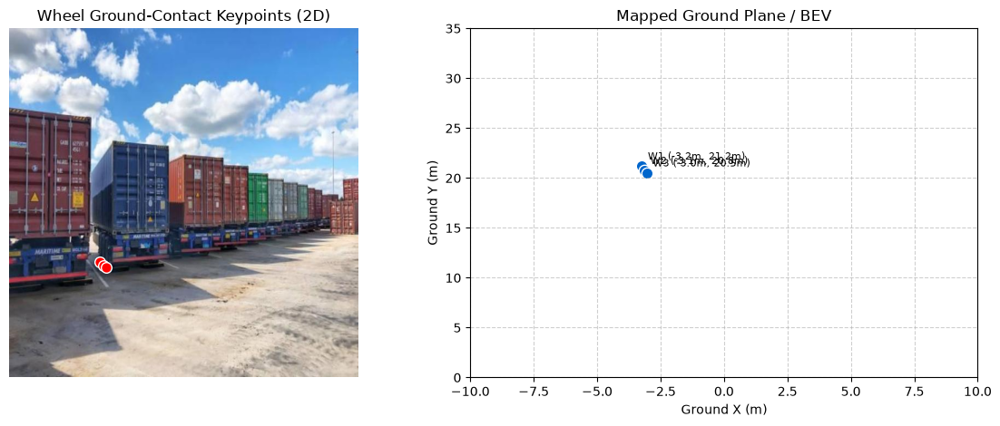

In [10]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

img_path = Path(
    "wheel_keypoints_v1/test/images/img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.jpg"
)
bgr = cv2.imread(str(img_path))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

pts_2d = np.array(
    [
        [166.19524, 427.8577],
        [172.32632, 434.52747],
        [177.38106, 438.10928],
    ],
    dtype=np.float32,
)

src_ground_px = [
    [w * 0.20, h * 0.65],
    [w * 0.80, h * 0.65],
    [w * 0.35, h * 0.92],
    [w * 0.65, h * 0.92],
]
dst_ground_m = [[-4.0, 22.0], [4.0, 22.0], [-2.5, 8.0], [2.5, 8.0]]
H, _ = cv2.findHomography(
    np.float32(src_ground_px), np.float32(dst_ground_m), cv2.RANSAC
)
ground_xy = cv2.perspectiveTransform(pts_2d.reshape(-1, 1, 2), H).reshape(-1, 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
ax1.imshow(rgb)
ax1.scatter(pts_2d[:, 0], pts_2d[:, 1], c="red", edgecolors="white", s=70)
ax1.set_title("Wheel Ground-Contact Keypoints (2D)")
ax1.axis("off")

ax2.grid(True, linestyle="--", alpha=0.6)
ax2.scatter(
    ground_xy[:, 0], ground_xy[:, 1], c="#0066cc", edgecolors="white", s=80
)
for i, (gx, gy) in enumerate(ground_xy):
  ax2.annotate(
      f"W{i+1} ({gx:.1f}m, {gy:.1f}m)",
      (gx, gy),
      textcoords="offset points",
      xytext=(5, 5),
      fontsize=8,
  )
ax2.set_xlim(-10, 10)
ax2.set_ylim(0, 35)
ax2.set_xlabel("Ground X (m)")
ax2.set_ylabel("Ground Y (m)")
ax2.set_title("Mapped Ground Plane / BEV")

plt.tight_layout()
plt.savefig("mentor_wheel_bev.png", dpi=150)
plt.show()

In [11]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np


def load_wheel_points(txt_file, img_w, img_h):
  pts = []
  label_file = Path(txt_file)
  if not label_file.exists():
    return np.zeros((0, 2), dtype=np.float32)

  with open(label_file, "r", encoding="utf-8") as f:
    for line in f:
      vals = list(map(float, line.strip().split()))
      if len(vals) < 3:
        continue
      coords = vals[1:]
      # Agar YOLO pose format (x, y, vis) hai toh vis > 0 check karo;
      # warna polygon/keypoint (x, y) pairs ke hisaab se padho
      if len(coords) % 3 == 0:
        for i in range(0, len(coords) - 2, 3):
          x_n, y_n, vis = coords[i], coords[i + 1], coords[i + 2]
          if vis > 0:
            pts.append([x_n * img_w, y_n * img_h])
      else:
        for i in range(0, len(coords) - 1, 2):
          pts.append([coords[i] * img_w, coords[i + 1] * img_h])

  return (
      np.asarray(pts, dtype=np.float32)
      if pts
      else np.zeros((0, 2), dtype=np.float32)
  )


def run_for_images(img_paths, labels_dir, src_ground_px, dst_ground_m, out_dir):
  out_path = Path(out_dir)
  out_path.mkdir(parents=True, exist_ok=True)

  H, _ = cv2.findHomography(
      np.asarray(src_ground_px, dtype=np.float32),
      np.asarray(dst_ground_m, dtype=np.float32),
      method=cv2.RANSAC,
  )

  for img_p in img_paths:
    img_p = Path(img_p)
    bgr = cv2.imread(str(img_p))
    if bgr is None:
      print("Skipping unreadable image:", img_p)
      continue

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]

    lbl_p = Path(labels_dir) / f"{img_p.stem}.txt"
    pts_2d = load_wheel_points(lbl_p, w, h)

    if len(pts_2d) > 0 and H is not None:
      ground_xy = cv2.perspectiveTransform(
          pts_2d.reshape(-1, 1, 2), H
      ).reshape(-1, 2)
    else:
      ground_xy = np.zeros((0, 2), dtype=np.float32)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
    ax1.imshow(rgb)
    if len(pts_2d) > 0:
      ax1.scatter(
          pts_2d[:, 0], pts_2d[:, 1], c="red", edgecolors="white", s=70
      )
    ax1.set_title(f"{img_p.name} — 2D Points ({len(pts_2d)})")
    ax1.axis("off")

    ax2.grid(True, linestyle="--", alpha=0.6)
    if len(ground_xy) > 0:
      ax2.scatter(
          ground_xy[:, 0], ground_xy[:, 1], c="#0066cc", edgecolors="white", s=80
      )
      for i, (gx, gy) in enumerate(ground_xy):
        ax2.annotate(
            f"W{i+1} ({gx:.1f}m, {gy:.1f}m)",
            (gx, gy),
            textcoords="offset points",
            xytext=(5, 5),
            fontsize=8,
        )
    ax2.set_xlim(-10, 10)
    ax2.set_ylim(0, 35)
    ax2.set_xlabel("Ground X (m)")
    ax2.set_ylabel("Ground Y (m)")
    ax2.set_title("Mapped Ground Plane / BEV")

    plt.tight_layout()
    save_file = out_path / f"bev_{img_p.stem}.png"
    plt.savefig(save_file, dpi=150)
    plt.close(fig)
    print(f"Saved: {save_file} | pts={len(pts_2d)}")


# Example: kisi split (train / valid / test) ki pehli 5 images par test karo
split = "test"
base = Path(r"C:\Dev\exotrac_paper\wheel_keypoints_v1")
sample_imgs = sorted((base / split / "images").glob("*.*"))[:5]

src_ground_px = [[128.0, 416.0], [512.0, 416.0], [224.0, 588.8], [416.0, 588.8]]
dst_ground_m = [[-4.0, 22.0], [4.0, 22.0], [-2.5, 8.0], [2.5, 8.0]]

run_for_images(
    img_paths=sample_imgs,
    labels_dir=base / split / "labels",
    src_ground_px=src_ground_px,
    dst_ground_m=dst_ground_m,
    out_dir="bev_batch_outputs",
)

Saved: bev_batch_outputs\bev_img-11_jpeg_jpg.rf.6b699fc6012b892c1f3e946c1b2f6dd2.png | pts=9
Saved: bev_batch_outputs\bev_img-29_jpeg_jpg.rf.c50f08a858167ca9585359ec491bb011.png | pts=6


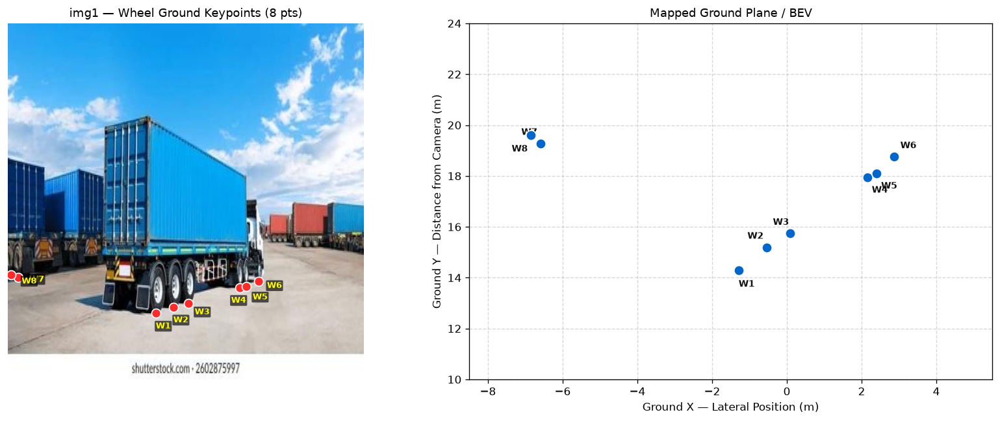


--- Ground Mapping Output (Format: Wheel | 2D Pixel -> Ground Meters) ---
W1 | 2D=(265.5, 520.6) px -> Ground X=-1.29m, Y=14.29m
W2 | 2D=(297.1, 509.6) px -> Ground X=-0.53m, Y=15.19m
W3 | 2D=(323.9, 502.9) px -> Ground X=0.09m, Y=15.74m
W4 | 2D=(416.5, 474.4) px -> Ground X=2.16m, Y=17.94m
W5 | 2D=(427.9, 472.2) px -> Ground X=2.41m, Y=18.10m
W6 | 2D=(449.9, 463.4) px -> Ground X=2.86m, Y=18.75m
W7 | 2D=(18.5, 456.0) px -> Ground X=-6.59m, Y=19.28m
W8 | 2D=(5.0, 451.5) px -> Ground X=-6.84m, Y=19.60m


In [20]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# EXPECTED OUTPUT FORMAT:
# ------------------------------------------------------------------------------
# W1 | 2D=(265.5, 520.6) px -> Ground X=-1.29m, Y=14.29m
# W2 | 2D=(297.1, 509.6) px -> Ground X=-0.53m, Y=15.19m
# ...
# Meaning:
#   - W1..W8     : Wheel ground-contact keypoint index
#   - 2D (u, v)  : Image pixel position (width, height)
#   - Ground X   : Left (-X) / Right (+X) distance in meters
#   - Ground Y   : Forward distance from camera in meters
# ==============================================================================

base = Path(r"C:\Dev\exotrac_paper\wheel_keypoints_v1")
img_name = "img1_png_jpg.rf.8d210fff0be9f09783e4f369d262020d.jpg"

img_path = base / "train" / "images" / img_name
label_path = base / "train" / "labels" / f"{Path(img_name).stem}.txt"

bgr = cv2.imread(str(img_path))
if bgr is None:
  raise FileNotFoundError(f"Image nahi mili: {img_path}")

rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
h, w = rgb.shape[:2]

pts = []
for line in label_path.read_text(encoding="utf-8").splitlines():
  vals = list(map(float, line.strip().split()))
  if len(vals) >= 7:
    kx, ky = vals[5], vals[6]
    vis = vals[7] if len(vals) >= 8 else 2.0
    if vis > 0:
      pts.append([kx * w, ky * h])

pts_2d = (
    np.asarray(pts, dtype=np.float32)
    if pts
    else np.zeros((0, 2), dtype=np.float32)
)

src_px = np.array(
    [[128.0, 416.0], [512.0, 416.0], [224.0, 588.8], [416.0, 588.8]],
    dtype=np.float32,
)
dst_m = np.array(
    [[-4.0, 22.0], [4.0, 22.0], [-2.5, 8.0], [2.5, 8.0]],
    dtype=np.float32,
)
H, _ = cv2.findHomography(src_px, dst_m, method=cv2.RANSAC)

ground_xy = (
    cv2.perspectiveTransform(pts_2d.reshape(-1, 1, 2), H).reshape(-1, 2)
    if len(pts_2d) > 0 and H is not None
    else np.zeros((0, 2), dtype=np.float32)
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

ax1.imshow(rgb)
if len(pts_2d) > 0:
  ax1.scatter(
      pts_2d[:, 0], pts_2d[:, 1], c="#ff2a2a", edgecolors="white", s=70, zorder=3
  )
  img_offsets = [
      (0, -14),
      (0, -14),
      (6, -10),
      (-8, -14),
      (6, -12),
      (8, -6),
      (10, -4),
      (10, -8),
  ]
  for i, (px, py) in enumerate(pts_2d):
    dx, dy = img_offsets[i % len(img_offsets)]
    ax1.annotate(
        f"W{i+1}",
        (px, py),
        textcoords="offset points",
        xytext=(dx, dy),
        color="yellow",
        fontsize=8,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.12",
            facecolor="black",
            alpha=0.65,
            edgecolor="none",
        ),
    )
ax1.set_title(f"img1 — Wheel Ground Keypoints ({len(pts_2d)} pts)", fontsize=11)
ax1.axis("off")

ax2.grid(True, linestyle="--", alpha=0.5)
if len(ground_xy) > 0:
  ax2.scatter(
      ground_xy[:, 0],
      ground_xy[:, 1],
      c="#0066cc",
      edgecolors="white",
      s=85,
      zorder=4,
  )
  bev_offsets = [
      (0, -15),
      (-18, 8),
      (-16, 8),
      (4, -14),
      (4, -14),
      (6, 8),
      (-18, 8),
      (-18, -15),
  ]
  for i, (gx, gy) in enumerate(ground_xy):
    dx, dy = bev_offsets[i % len(bev_offsets)]
    ax2.annotate(
        f"W{i+1}",
        (gx, gy),
        textcoords="offset points",
        xytext=(dx, dy),
        fontsize=8.5,
        fontweight="bold",
        color="#111111",
    )

ax2.set_xlim(-8.5, 5.5)
ax2.set_ylim(10, 24)
ax2.set_xlabel("Ground X — Lateral Position (m)")
ax2.set_ylabel("Ground Y — Distance from Camera (m)")
ax2.set_title("Mapped Ground Plane / BEV", fontsize=11)

plt.tight_layout()
plt.show()

print("\n--- Ground Mapping Output (Format: Wheel | 2D Pixel -> Ground Meters) ---")
for i, ((ux, uy), (gx, gy)) in enumerate(zip(pts_2d, ground_xy)):
  print(
      f"W{i+1} | 2D=({ux:.1f}, {uy:.1f}) px -> Ground X={gx:.2f}m, Y={gy:.2f}m"
  )